# Week 6: HydroHype Smart Water Bottle — Study Design & Power Analysis

**Author:** Natalie Zachariah

## Background / Overview
Our client, HydroHype, makes a smart water bottle and makes the following claim:

> **Carrying the HydroHype smart water bottle increases average daily water consumption by at least 500 mL compared with a standard bottle.**

In this notebook we design a hypothesis-driven study to test that claim, choose a statistical test, estimate an effect size from the literature, and run a power analysis to find the required sample size. We give the rationale for each decision.

## 1. Study Design

**Design:** A two-arm, parallel-group **randomized controlled trial (RCT)** lasting **2 weeks**.

| Element | Choice |
|---|---|
| Participants | Healthy adults (18–65) |
| Treatment group | Carries a HydroHype smart bottle (tracking + reminders) |
| Control group | Carries a **standard bottle of the same size** (no smart features) |
| Assignment | Random assignment, 1:1 |
| Duration | 2 weeks |
| Outcome | Average daily water intake (mL/day) over the 2 weeks |
| Measurement | **Same method for both groups**: a standardized intake diary or 24-hour urine volume |

**Rationale:**
- **Why randomize?** Randomization balances confounders such as activity level, climate, body size and baseline drinking habits across the groups. Any difference in intake can then be attributed to the bottle.
- **Why give the control group a bottle too?** If the control group had no bottle, we would be testing whether having *any* bottle helps. A same-size standard bottle means we are testing the **smart features** (tracking and reminders), which is what the claim is about.
- **Why measure both groups the same way?** The HydroHype bottle logs intake automatically and a standard bottle cannot. If we used the bottle's own log for the treatment group and a diary for the control group, part of any difference could come from the measurement method rather than the bottle. That would be **measurement bias**, so we use one common, independent measure for everyone.

## 2. Null and Alternative Hypotheses

Let $\mu_{diff} = \mu_{HydroHype} - \mu_{standard}$, the difference in mean daily water consumption (mL/day) between the HydroHype group and the standard bottle group.

- **Null hypothesis, $H_0$:** $\mu_{diff} = 0$. Mean daily water consumption with the HydroHype bottle is the same as with a standard bottle (the smart bottle makes no difference).
- **Alternative hypothesis, $H_1$:** $\mu_{diff} \neq 0$. Mean daily water consumption with the HydroHype bottle differs from a standard bottle (two-sided).

**Rationale:**
- **Why two-sided?** A two-sided test is more conservative than a one-sided test. It would also detect the bottle *lowering* intake, for example if people come to rely on the reminders and drink less without them.
- **Where does the 500 mL go?** We use the claimed **500 mL/day increase as the effect size we power the study for** (Section 4). We do *not* test $H_0: \mu_{diff} \le 500$ directly. That test would show the effect is *greater than* 500 mL, which is a much harder bar: if the true effect were exactly 500 mL, the power to reject would be no better than chance ($\approx \alpha$). The claim says "at least 500 mL", so we note this wording. Our design tests whether the bottle has an effect and is sized to reliably detect an effect of 500 mL. We then report the estimated difference with a 95% confidence interval and compare it with the 500 mL figure.

## 3. Statistical Test

We will use **Welch's independent two-sample t-test** (two-sided).

**Rationale:**
- The outcome (mL/day) is **continuous**, and the two groups are **independent** because each participant is randomly assigned to exactly one group. That makes an independent-samples t-test appropriate.
- We chose **Welch's** version because it does not assume equal variances. The smart bottle might push some people to drink much more while others ignore it, so the HydroHype group could be more spread out than the control group.
- **Normality assumption:** daily water intake is somewhat right-skewed. With about 100+ participants per group, the central limit theorem makes the sampling distribution of the mean difference approximately normal, so the t-test is robust.
- **Backup:** we will also run a **Mann-Whitney U test** as a sensitivity check that does not rely on normality.
- **Optional extension:** record intake during a baseline week before randomization and analyze with **ANCOVA** (adjusting for baseline intake). This removes between-person variance and would reduce the required sample size.

## 4. Literature Exploration for Effect Size

**Effect size type:** Cohen's d

$$d = \frac{\text{claimed difference}}{SD} = \frac{500 \text{ mL/day}}{SD \text{ of daily water intake}}$$

The claim gives us the numerator (500 mL/day). For the denominator, we need the between-person standard deviation of daily water intake from the literature.

**Finding the SD:**
- A study of adult water intake ([Montclair State University thesis, "An Assessment of Daily Plain Water Intake Level and Its..."](https://digitalcommons.montclair.edu/cgi/viewcontent.cgi?article=1116&context=etd)) reported, in one adult age subgroup, **plain water intake of 1577 ± 1150 mL/day** and **total water intake of 2582 ± 1300 mL/day**.
- A validation study of a water frequency questionnaire against deuterium oxide (D₂O) found that the questionnaire underestimated total water intake by **−350 ± 1,431 mL/day** ([Validity and Reliability of a Water Frequency Questionnaire to Estimate Daily Total Water Intake in Adults, PMC8236537](https://pmc.ncbi.nlm.nih.gov/articles/PMC8236537/)). This supports a between-person SD on the order of 1,100–1,400 mL/day and shows that self-reported intake is noisy.

**Converting to Cohen's d:**
- $d = 500 / 1300 \approx 0.385$ (conservative, based on total water intake SD)
- $d = 500 / 1150 \approx 0.435$ (based on plain water intake SD)

**Plausibility check:** In a randomized trial of kidney stone formers ([A Randomized Trial Evaluating the Use of a Smart Water Bottle to Increase Fluid Intake in Stone Formers, J Ren Nutr 2022, PubMed 35283036](https://pubmed.ncbi.nlm.nih.gov/35283036/)), 24-hour urine volume rose by **1.37 L** with a HidrateSpark smart bottle versus **0.79 L** with dietary advice alone, a difference of about **580 mL**. This suggests a 500 mL effect is realistic. However, those patients had a strong medical reason to drink more, so the effect in the general public is likely smaller.

**Our choice: d = 0.385.** We chose the more conservative value because published effects tend to be inflated and the general population is less motivated than kidney stone patients. A smaller d gives a larger sample size, which protects us against underpowering the study.

In [1]:
import numpy as np

claimed_diff = 500   # mL/day, from the client's claim
sd_total = 1300      # mL/day, SD of total water intake (literature)
sd_plain = 1150      # mL/day, SD of plain water intake (literature)

d_total = claimed_diff / sd_total
d_plain = claimed_diff / sd_plain

print(f"Cohen's d using total-water SD (1300): {d_total:.3f}")
print(f"Cohen's d using plain-water SD (1150): {d_plain:.3f}")

effect_size = d_total  # chosen (conservative) effect size

Cohen's d using total-water SD (1300): 0.385
Cohen's d using plain-water SD (1150): 0.435


## 5. Power Analysis

We now run the power analysis with these parameters:

| Input | Value | Reason |
|---|---|---|
| Effect size (Cohen's d) | 0.385 (exactly 500/1300 = 0.3846) | 500 mL / 1300 mL SD; the conservative estimate from the literature |
| Significance level ($\alpha$) | 0.05 | Standard choice; 5% false-positive rate |
| Power | 0.80 | Standard choice; 80% chance of detecting a true 500 mL effect |
| Alternative | two-sided | Matches our hypotheses (Section 2) |
| Group size ratio | 1.0 | Equal 1:1 randomization is the most efficient design |
| Dropout | 15% | Assumed attrition over the 2-week study |

`TTestIndPower` uses the pooled-variance t-test formula. With equal group sizes this is a close approximation to Welch's test.

In [2]:
import math
from statsmodels.stats.power import TTestIndPower

alpha = 0.05
power = 0.80
dropout = 0.15

analysis = TTestIndPower()
n = analysis.solve_power(effect_size=effect_size, alpha=alpha, power=power,
                         ratio=1.0, alternative='two-sided')
required_n = math.ceil(n)
n_recruit = math.ceil(required_n / (1 - dropout))

print(f"Cohen's d = {effect_size:.3f}")
print(f"Required n per group = {required_n}")
print(f"Recruit per group (15% dropout) = {n_recruit}, total = {2 * n_recruit}")

Cohen's d = 0.385
Required n per group = 108
Recruit per group (15% dropout) = 128, total = 256


### Sensitivity analysis
The true effect could be smaller or larger than our estimate. The table below shows how the required sample size per group changes with d, and with a one-sided test or 90% power.

In [3]:
import pandas as pd

rows = []
for d in [0.30, effect_size, 0.435, 0.50]:
    rows.append({
        "Cohen's d": round(d, 3),
        "n/group (two-sided, 80%)": math.ceil(analysis.solve_power(effect_size=d, alpha=alpha, power=0.80, alternative='two-sided')),
        "n/group (one-sided, 80%)": math.ceil(analysis.solve_power(effect_size=d, alpha=alpha, power=0.80, alternative='larger')),
        "n/group (two-sided, 90%)": math.ceil(analysis.solve_power(effect_size=d, alpha=alpha, power=0.90, alternative='two-sided')),
    })
sensitivity = pd.DataFrame(rows)
sensitivity

,Cohen's d,"n/group (two-sided, 80%)","n/group (one-sided, 80%)","n/group (two-sided, 90%)"
0,0.300,176,139,235
1,0.385,108,85,144
2,0.435,84,67,113
3,0.500,64,51,86


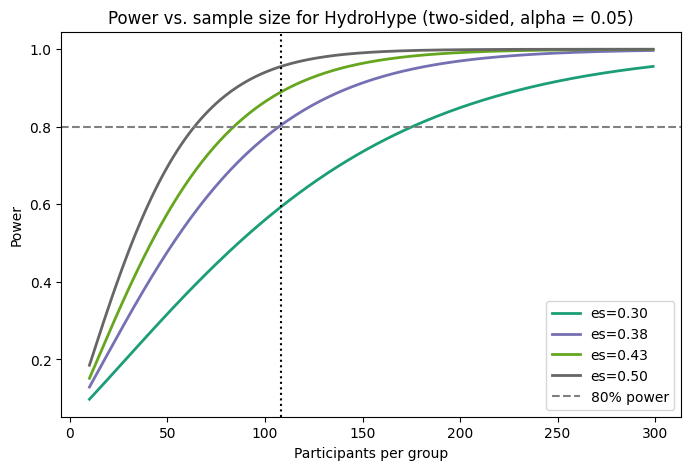

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
analysis.plot_power(dep_var='nobs', nobs=np.arange(10, 300),
                    effect_size=[0.30, effect_size, 0.435, 0.50], alpha=alpha, ax=ax)
ax.axhline(0.80, ls='--', c='gray', label='80% power')
ax.axvline(required_n, ls=':', c='black')
ax.set_xlabel('Participants per group')
ax.set_ylabel('Power')
ax.set_title('Power vs. sample size for HydroHype (two-sided, alpha = 0.05)')
ax.legend()
plt.show()

## 6. Results and Conclusions

To detect the claimed **500 mL/day** increase in water consumption (Cohen's **d ≈ 0.385**, based on a literature SD of 1300 mL/day) with $\alpha = 0.05$ and **80% power** using a two-sided Welch's t-test, the required sample size is **108 participants per group**. Allowing for 15% dropout over the 2 weeks, we will **recruit 128 participants per group (256 total)**.

**Interpretation:**
- A study of about 256 adults over 2 weeks is feasible for a consumer-product trial.
- The sensitivity analysis shows the sample size depends heavily on the true effect. If the real effect is smaller than claimed (d = 0.30, about 390 mL/day), we would need about **176 per group**, so our study would be underpowered for an effect well below the claim.
- If the client wants a stronger guarantee, 90% power at d = 0.385 needs 144 per group (170 per group after dropout).
- After the study, we will report the estimated mean difference and its 95% confidence interval. If the lower bound of the CI is above 500 mL/day, that would support the "at least 500 mL" wording. A significant result alone only shows the bottle has *some* effect.

**Order of decisions:** We chose the significance level ($\alpha = 0.05$), the power (0.80) and the statistical test (two-sided Welch's t-test) **before** finding the effect size. We then estimated the effect size from the literature and ran the power analysis.

## References
1. [An Assessment of Daily Plain Water Intake Level and Its... (Montclair State University thesis)](https://digitalcommons.montclair.edu/cgi/viewcontent.cgi?article=1116&context=etd): source of the plain water (1577 ± 1150 mL/day) and total water (2582 ± 1300 mL/day) intake figures.
2. [Validity and Reliability of a Water Frequency Questionnaire to Estimate Daily Total Water Intake in Adults (PMC8236537)](https://pmc.ncbi.nlm.nih.gov/articles/PMC8236537/)
3. [A Randomized Trial Evaluating the Use of a Smart Water Bottle to Increase Fluid Intake in Stone Formers (J Ren Nutr, 2022; PubMed 35283036)](https://pubmed.ncbi.nlm.nih.gov/35283036/)
4. [Drewnowski A, Rehm CD, Constant F. Water and beverage consumption among adults in the United States: NHANES 2005–2010 (BMC Public Health, 2013)](https://pmc.ncbi.nlm.nih.gov/articles/PMC3840570/): background on typical U.S. adult water intake.